# 05 — Design of the experiment

**Question:** how can I test whether the tracks chosen by the MILP are skipped less often than tracks chosen without the predictions, with free listening and a skip rate of a few percent? How many plays does the test need, and does the identification of the experimental plays work?

**Data:** the most recent part of the history (2026-09-20 to 2026-10-20, and since 2026-07-01 as a check), on the rows of the model (`model_rows`) with a known previous track; simulations calibrated on these numbers; the weekly playlists of `src/experiment.py`.

**Metric:** skip rate (`fwdbtn` against `trackdone`, as in the model); power of a one-sided test at the 5% level.

In [1]:
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import expit, logit

sys.path.append("../src")
from analysis import experiment_plays, permutation_test
from experiment import plan_weeks
from features import ROOT
from train import MODEL_PATH, model_rows

df = pd.read_parquet(ROOT / "data" / "features.parquet")

# Days and half days in local time (the experiment runs in Germany)
df["local"] = df["ts"].dt.tz_convert("Europe/Berlin")
df["day"] = df["local"].dt.floor("D")
df["half_day"] = df["day"].astype(str) + np.where(df["local"].dt.hour < 14, " am", " pm")

# Last month of the history, and the period since July as a check
RECENT = pd.Timestamp("2026-09-20", tz="Europe/Berlin")
JULY = pd.Timestamp("2026-07-01", tz="Europe/Berlin")
END = pd.Timestamp("2026-10-21", tz="Europe/Berlin")

## Recent listening

In [2]:
recent = df[(df["local"] >= RECENT) & (df["local"] < END)]
per_day = recent.groupby("day").agg(
    hours=("ms_played", lambda s: s.sum() / 3.6e6), plays=("ms_played", "size")
)
print(f"days with listening: {len(per_day)} of {(END - RECENT).days}")
print(f"share in shuffle: {recent['shuffle'].mean():.3f}")
per_day.agg(["mean", "median"]).round(2)

days with listening: 31 of 31
share in shuffle: 0.649


,hours,plays
mean,2.62,58.87
median,2.42,60.00


In [3]:
# Rows of the model with a known previous track (the chain of skips needs it)
rows = model_rows(df)
rows = rows[rows["prev_y"].notna()]
periods = {
    "since 2026-09-20": rows[(rows["local"] >= RECENT) & (rows["local"] < END)],
    "since 2026-07-01": rows[rows["local"] >= JULY],
}


def skip_rates(r):
    """Skip rate overall, after a non-skipped and after a skipped track, and the logit shift."""
    a = r.loc[r["prev_y"] == 0, "y"].mean()
    b = r.loc[r["prev_y"] == 1, "y"].mean()
    stats = {
        "n": len(r), "rate": r["y"].mean(), "after_no_skip": a, "after_skip": b,
        "logit_shift": logit(b) - logit(a),
    }
    return pd.Series(stats)


pd.DataFrame({name: skip_rates(r) for name, r in periods.items()}).T.round(3)

,n,rate,after_no_skip,after_skip,logit_shift
since 2026-09-20,1158.0,0.072,0.043,0.486,3.040
since 2026-07-01,5199.0,0.188,0.096,0.577,2.552


## Correlation within day and session

In [4]:
def icc(y, groups):
    """Intraclass correlation of y within groups (one-way ANOVA estimator)."""
    g = y.groupby(groups)
    n_i, k, n = g.size(), g.ngroups, len(y)
    msb = (n_i * (g.mean() - y.mean()) ** 2).sum() / (k - 1)
    msw = ((y - g.transform("mean")) ** 2).sum() / (n - k)
    # Mean group size, corrected for unequal sizes
    n0 = (n - (n_i ** 2).sum() / n) / (k - 1)
    return (msb - msw) / (msb + (n0 - 1) * msw)


table = {
    name: {g: icc(r["y"], r[g]) for g in ["day", "half_day", "session_id"]}
    for name, r in periods.items()
}
pd.DataFrame(table).T.round(3)

,day,half_day,session_id
since 2026-09-20,0.051,0.089,0.191
since 2026-07-01,0.116,0.175,0.265


In [5]:
# One playlist per day (days A/B): m plays in a day are worth m / (1 + (m - 1) * ICC)
# independent plays (design effect); m = 40, about one hour of listening
m = 40
for name, t in table.items():
    deff = 1 + (m - 1) * t["day"]
    print(f"{name}: design effect {deff:.1f}, {m} plays worth {m / deff:.0f} independent plays")

since 2026-09-20: design effect 3.0, 40 plays worth 13 independent plays
since 2026-07-01: design effect 5.5, 40 plays worth 7 independent plays


## Simulator

Each simulated session is a chain of skips: the logit of a skip is the control level, plus a random effect of the day and of the session, plus the log odds ratio for MILP tracks, plus a shift after a skipped track. Sessions have a geometric length and every track is in the MILP arm with probability 1/2, as in the shuffled playlist.

In [6]:
P0_CONTROL = 0.035  # skip probability of a control track after a non-skip (no random effects)
SHIFT = 2.5  # logit shift after a skipped track (table above: 3.0 recent, 2.55 since July)
SD_DAY = 0.4  # standard deviation of the day effect on the logit
SD_SESSION = 0.8  # standard deviation of the session effect on the logit
MEAN_SESSION = 15  # mean number of experimental plays in a session (geometric)
SESSIONS_PER_DAY = 2


def simulate(n_plays, odds_ratio, rng):
    """Simulated interleaving experiment: one row per play with session, day, arm and skip."""
    # Sessions of geometric length, the last one cut to reach exactly n_plays
    lengths = rng.geometric(1 / MEAN_SESSION, n_plays)
    lengths = lengths[:np.searchsorted(lengths.cumsum(), n_plays) + 1]
    lengths[-1] -= lengths.sum() - n_plays
    session = np.repeat(np.arange(len(lengths)), lengths)
    day = session // SESSIONS_PER_DAY
    # Random effects on the logit: one for the day, one for the session
    u_day = rng.normal(0, SD_DAY, day[-1] + 1)
    u_session = rng.normal(0, SD_SESSION, len(lengths))
    # Each track is in the MILP arm with probability 1/2 (random order in the playlist)
    milp = rng.random(n_plays) < 0.5
    base = logit(P0_CONTROL) + np.log(odds_ratio) * milp + u_day[day] + u_session[session]
    first = np.r_[True, session[1:] != session[:-1]]
    r = rng.random(n_plays)
    y = np.zeros(n_plays, dtype=bool)
    for i in range(n_plays):
        # Chain of skips: after a skip in the same session the logit grows by SHIFT
        prev = y[i - 1] and not first[i]
        y[i] = r[i] < expit(base[i] + SHIFT * prev)
    return pd.DataFrame({"session_id": session, "day": day, "milp": milp, "y": y})

In [7]:
# Calibration: a long simulation without effect, compared with the tables above
rng = np.random.default_rng(0)
sim = simulate(200_000, 1.0, rng)
sim["y"] = sim["y"].astype(float)
sim["prev_y"] = sim.groupby("session_id")["y"].shift(1)

print(skip_rates(sim[sim["prev_y"].notna()]).round(3).to_string(), "\n")
print(f"ICC day {icc(sim['y'], sim['day']):.3f}, session {icc(sim['y'], sim['session_id']):.3f}")

n                186562.000
rate                  0.083
after_no_skip         0.045
after_skip            0.519
logit_shift           3.133 

ICC day 0.121, session 0.181


## Power of the interleaving test

In [8]:
def power(n_plays, odds_ratio, reps=300, n_perm=500, seed=0):
    """Share of simulated experiments in which the test rejects H0 at the 5% level."""
    rng = np.random.default_rng(seed)
    p_values = []
    for _ in range(reps):
        d = simulate(n_plays, odds_ratio, rng)
        p_values.append(permutation_test(d["y"], d["milp"], d["session_id"], n_perm, rng)[1])
    return np.mean(np.array(p_values) < 0.05)


# Type I error: no effect, the test should reject in about 5% of the experiments
print(f"type I error at 1,700 plays: {power(1700, 1.0, reps=2000):.3f}")

type I error at 1,700 plays: 0.038


In [9]:
N_PLAYS = [300, 500, 800, 1200, 1700, 2000]
grid = {f"odds ratio {o}": {n: power(n, o) for n in N_PLAYS} for o in [0.5, 0.7]}
pd.DataFrame(grid).T.round(2)

,300,500,800,1200,1700,2000
odds ratio 0.5,0.16,0.33,0.46,0.65,0.80,0.83
odds ratio 0.7,0.08,0.11,0.19,0.31,0.42,0.46


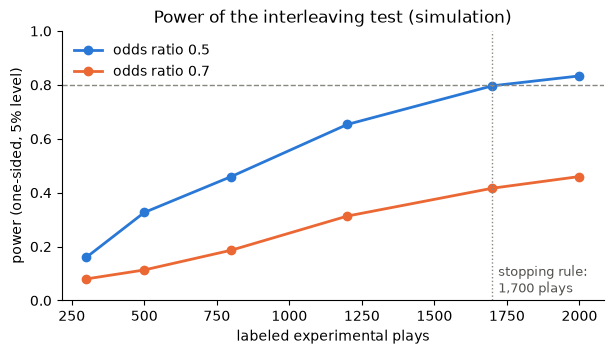

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for (name, row), color in zip(grid.items(), ["#2a78d6", "#eb6834"]):
    ax.plot(N_PLAYS, list(row.values()), "o-", color=color, lw=2, label=name)
ax.axhline(0.8, color="#898781", lw=1, linestyle="--")
ax.axvline(1700, color="#898781", lw=1, linestyle=":")
ax.text(1720, 0.03, "stopping rule:\n1,700 plays", color="#52514e", fontsize=9)
ax.set_ylim(0, 1)
ax.set_xlabel("labeled experimental plays")
ax.set_ylabel("power (one-sided, 5% level)")
ax.set_title("Power of the interleaving test (simulation)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
fig.savefig(ROOT / "results" / "power.png", dpi=150, bbox_inches="tight")
plt.show()

## Contrast between the arms over the experiment

In [11]:
streams = pd.read_parquet(ROOT / "data" / "streams_clean.parquet")
pool = pd.read_parquet(ROOT / "data" / "pool.parquet")
model = joblib.load(MODEL_PATH)

# All the weeks until the end of the experiment, built in memory with the same rotation:
# the files in data/experiment are neither read nor written
mondays = pd.date_range("2026-10-26", "2027-03-29", freq="7D")
plan = plan_weeks(streams, pool, model, mondays)

In [12]:
# Only totals per arm are shown: which track is in which arm stays hidden (blind test)
mean_p0 = plan.groupby(["monday", "arm"])["p0"].mean().unstack()
odds = mean_p0 / (1 - mean_p0)
mean_p0["odds_ratio"] = odds["milp"] / odds["control"]
print(mean_p0["odds_ratio"].describe()[["min", "mean", "max"]].round(3).to_string(), "\n")

# Share of new tracks per arm: same limits (10% to 40%), but within them the MILP prefers new
# tracks, which the model predicts with a low skip probability
print(plan.groupby("arm")["is_new"].mean().round(3).to_string(), "\n")

# How often the same track comes back: distinct tracks and maximum number of uploads per arm
plan.groupby(["arm", "track_uri"]).size().groupby("arm").agg(["size", "max"])

min     0.460
mean    0.510
max     0.597 

arm
control    0.134
milp       0.287 



,size,max
arm,,
control,1775,4
milp,523,5


## Identification of the experimental plays

In [13]:
# Free listening in 2026, before the experiment: each week, one of the weekly playlists above
# as if it had been active. Every play that the rule finds is a false positive
fake_mondays = pd.date_range("2026-01-05", "2026-10-19", freq="7D", tz="Europe/Berlin")
fake = pd.concat(
    plan.loc[plan["monday"] == mondays[i % len(mondays)], ["track_uri"]].assign(uploaded=m)
    for i, m in enumerate(fake_mondays)
)
free = df[df["local"] >= fake_mondays[0]]

n_weeks = len(fake_mondays)
print(f"{n_weeks} weeks, {len(free) / n_weeks:.0f} plays per week")
found = {k: experiment_plays(free, fake, min_run=k).sum() / n_weeks for k in [1, 2, 3, 4]}
pd.Series(found, name="false plays per week").rename_axis("min_run").round(2)

42 weeks, 491 plays per week


min_run
1    15.60
2     2.29
3     0.14
4     0.00
Name: false plays per week, dtype: float64

## Conclusions

- **Recent listening.** Every day from 2026-09-20 to 2026-10-20, on average 2.62 hours and 59 plays a day. Skip rate on the rows of the model 7.2% (4.3% after a non-skipped track, 48.6% after a skip): skips are rare and come in runs.
- **Correlation.** ICC 0.051 within the day, 0.089 within the half day, 0.191 within the session (0.116, 0.175 and 0.265 since July). With one playlist per day, 40 plays would be worth 7 to 13 independent plays (design effect 3.0 to 5.5). **Decision: interleaving**, the two arms mixed in the same playlist and compared within the same sessions.
- **Simulator.** Chain of skips with random effects of the day and of the session, calibrated on the data: skip rate 8.3% (data 7.2%), ICC of the session 0.181 (0.191). Slightly noisier than the data, so the power below is cautious.
- **Test.** Permutation test with the arm labels permuted within each session (`src/analysis.py`): type I error 0.038 at 1,700 plays over 2,000 simulated experiments. Valid, and slightly conservative because of ties.
- **Power** (one-sided, 5% level): 0.80 at 1,700 plays with the effect predicted by the model (odds ratio 0.5), only 0.42 with an odds ratio of 0.7. **Decision: stop at 1,700 labeled experimental plays or on 2027-03-31** (`docs/experiment_protocol.md`). With a smaller effect the result is an estimate with a confidence interval, not a significant test.
- **Contrast between the arms.** Over the 23 weekly playlists until the end of March, the odds ratio of the mean `p0` (MILP against control) stays between 0.460 and 0.597, mean 0.510: the 4-week rotation does not wear out the contrast. Within the same limits (10% to 40%) the MILP arm has more new tracks than the control arm, 28.7% against 13.4%, because the model predicts low skip probabilities for new tracks: the results for known and new tracks are reported separately. The MILP arm uses 523 distinct tracks, each uploaded at most 5 times; the control arm 1,775 tracks, at most 4 times.
- **Identification of the experimental plays.** On the free listening of 2026, with the weekly playlists as if they had been active, tracks of the playlist appear 15.6 times a week; requiring runs of at least 3 plays brings the false experimental plays down to 0.14 a week. **Decision: runs of at least 3 (`MIN_RUN` in `src/analysis.py`).**